# BERTilda — comparação de janelas e embeddings

Este é o notebook principal para explorar o piloto de 2015–2017. Compara embeddings contextuais e lexicais com janelas anuais, semestrais, mensais e semanais. Não gera novos embeddings. Uma intervenção é um documento; as semanas começam à segunda-feira e as semanas nas extremidades podem ser parciais.

O acompanhamento temporal implementado é uma **aproximação exploratória** ao BERTilda, não uma reprodução integral das regras do artigo. O objetivo é avaliar os resultados com dados e leituras, não demonstrar automaticamente que o método funciona.


## Resultados iniciais já disponíveis

Estes resultados são da experiência anual anterior, antes da correção dos acentos, e usam configuração lexical diferente da experiência abaixo. Servem apenas como ponto de partida; os resultados anuais corrigidos e das outras janelas são produzidos ao executar o resto do notebook.


In [11]:
from pathlib import Path
import csv
from collections import Counter

paths = [Path("../../data/bertilda_annual/comparacao_2015_2017_v1"), Path("data/bertilda_annual/comparacao_2015_2017_v1")]
anterior = next((p for p in paths if p.exists()), None)
if anterior is None:
    print("Resultados anuais anteriores não encontrados; continua para a nova experiência.")
else:
    print("Resultados anuais anteriores: descritores com acentos corrompidos; apenas referência histórica.")
    for versao in ["contextual", "lexical"]:
        print(f"\n{versao.upper()}")
        with (anterior / versao / "diagnosticos.csv").open(encoding="utf-8") as ficheiro:
            for linha in csv.DictReader(ficheiro):
                print(f"  {linha['ano']}: {linha['documentos']} intervenções, {linha['topicos_validos']} tópicos, ruído {float(linha['proporcao_ruido']):.1%}")
        with (anterior / versao / "topicos.csv").open(encoding="utf-8") as ficheiro:
            for linha in csv.DictReader(ficheiro):
                print(f"  {linha['ano']} — tópico {linha['topico']} ({linha['intervencoes']}): {linha['palavras']}")
        with (anterior / versao / "eventos.csv").open(encoding="utf-8") as ficheiro:
            contagem = Counter(linha["tipo"] for linha in csv.DictReader(ficheiro))
        print("  Eventos candidatos: " + ", ".join(f"{tipo}: {numero}" for tipo, numero in contagem.items()))


Resultados anuais anteriores: descritores com acentos corrompidos; apenas referência histórica.

CONTEXTUAL
  2015: 11379 intervenções, 4 tópicos, ruído 1.3%
  2016: 12104 intervenções, 6 tópicos, ruído 1.4%
  2017: 12775 intervenções, 7 tópicos, ruído 1.3%
  2015 — tópico 0 (10753): sr, governo, tambm, presidente, srs, sr presidente, deputados, so, srs deputados, porque
  2015 — tópico 1 (281): declarao voto, voto, declarao, anunciar, sr presidente, presidente, voto sobre, votao, apresentar declarao, presidente anunciar
  2015 — tópico 2 (133): baixa, comisso, pcp, baixa comisso, be, lei, recomenda, recomenda governo, alterao, freguesia
  2015 — tópico 3 (62): interpelao mesa, mesa, interpelao, peo, presidente peo, sr presidente, presidente, palavra, mesa sobre, sobre conduo
  2016 — tópico 0 (11394): sr, governo, srs, tambm, presidente, deputados, sr presidente, srs deputados, so, porque
  2016 — tópico 1 (151): declarao voto, declarao, voto, apresentar declarao, votao, apresentar, g

In [12]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from bertopic import BERTopic
from hdbscan import HDBSCAN
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import adjusted_rand_score
from umap import UMAP
from IPython.display import display


In [13]:
RANDOM_STATE = 42
YEARS = [2015, 2016, 2017]
VERSOES = ["contextual", "lexical"]
JANELAS = ["anual", "semestral", "mensal", "semanal"]
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
MAX_SEQ_LENGTH = 512
UMAP_NEIGHBORS = 15
HDBSCAN_SELECTION = "eom"
MIN_CLUSTER_SIZE = 20
MIN_DOCS_PER_TOPIC = 20
TOP_N_WORDS = 10
SIMILARITY_THRESHOLD = 0.70
DOCUMENT_TOPIC_THRESHOLD = 0.40
COVERAGE_THRESHOLD = 0.30
SPLIT_COVERAGE_THRESHOLD = 0.70
MERGE_COVERAGE_THRESHOLD = 0.70
NOME_EXPERIENCIA = "comparacao_quatro_janelas_v2_min20"


## 1. Carregar dados e embeddings

Os dois corpus têm os mesmos IDs. O carregamento verifica a assinatura dos textos e a ordem de todos os blocos. Pode demorar alguns minutos.


In [14]:
data_dir = next((p.resolve() for p in [Path("../../data"), Path("data")]
                 if (p / "parlamint_pt_corpus_contextual.csv").exists()), None)
if data_dir is None:
    raise FileNotFoundError("Não foram encontrados os corpus em data.")
nome_anos = "anos_" + "_".join(map(str, YEARS))
embedding_base = data_dir / "embeddings_bertimbau" / nome_anos
output_base = data_dir / "bertilda_annual" / NOME_EXPERIENCIA
if len(set(YEARS)) != len(YEARS) or YEARS != sorted(YEARS) or any(b - a != 1 for a, b in zip(YEARS, YEARS[1:])):
    raise ValueError("YEARS deve conter anos únicos, consecutivos e por ordem crescente.")

def assinatura_corpus(ids, textos, versao, chunk_size):
    h = hashlib.sha256()
    config = {"modelo": MODEL_NAME, "max_seq_length": MAX_SEQ_LENGTH, "pooling": "mean",
              "normalize_embeddings": True, "versao": versao, "chunk_size": chunk_size}
    h.update(json.dumps(config, sort_keys=True).encode())
    for identificador, texto in zip(ids, textos):
        for valor in (identificador, texto):
            dados = valor.encode("utf-8")
            h.update(len(dados).to_bytes(8, "big"))
            h.update(dados)
    return h.hexdigest()

def carregar_versao(versao):
    ficheiro = data_dir / f"parlamint_pt_corpus_{versao}.csv"
    corpus = pd.read_csv(ficheiro, dtype="string", keep_default_na=False)
    if not {"ID", "Date", "texto_modelo"}.issubset(corpus.columns):
        raise ValueError(f"Colunas necessárias em falta: {ficheiro}")
    corpus["ano"] = pd.to_datetime(corpus["Date"], errors="coerce").dt.year
    corpus = corpus.loc[corpus["ano"].isin(YEARS)].sort_values("ID").reset_index(drop=True)
    if corpus.empty or corpus["ID"].eq("").any() or corpus["ID"].duplicated().any() or corpus["texto_modelo"].str.strip().eq("").any():
        raise ValueError(f"Corpus vazio ou com IDs/textos inválidos: {ficheiro}")
    if set(corpus["ano"].unique()) != set(YEARS):
        raise ValueError(f"Faltam anos em {ficheiro}")
    pasta = embedding_base / versao
    manifesto = json.loads((pasta / "manifesto.json").read_text(encoding="utf-8"))
    chunk_size = int(manifesto["chunk_size"])
    ids = corpus["ID"].astype(str).tolist()
    textos = corpus["texto_modelo"].astype(str).tolist()
    assinatura = assinatura_corpus(ids, textos, versao, chunk_size)
    if manifesto["assinatura"] != assinatura or manifesto["documentos"] != len(ids) or manifesto["modelo"] != MODEL_NAME or manifesto["versao"] != versao:
        raise ValueError(f"O manifesto não corresponde ao corpus ou modelo: {pasta}")
    blocos = []
    dimensao = None
    for inicio in range(0, len(ids), chunk_size):
        fim = min(inicio + chunk_size, len(ids))
        caminho = pasta / f"bloco_{inicio:08d}_{fim:08d}.npz"
        if not caminho.exists():
            raise FileNotFoundError(f"Bloco de embeddings em falta: {caminho}")
        with np.load(caminho, allow_pickle=False) as bloco:
            vetores = bloco["embeddings"]
            if not np.array_equal(bloco["document_ids"].astype(str), np.asarray(ids[inicio:fim])):
                raise ValueError(f"IDs desalinhados no bloco: {caminho}")
            if vetores.ndim != 2 or vetores.shape[0] != fim - inicio or not np.isfinite(vetores).all():
                raise ValueError(f"Embeddings inválidos: {caminho}")
            if dimensao is None:
                dimensao = vetores.shape[1]
            if vetores.shape[1] != dimensao:
                raise ValueError(f"Dimensão inconsistente: {caminho}")
            blocos.append(vetores)
    corpus = corpus.rename(columns={"texto_modelo": "documento_modelo"})
    return corpus, np.concatenate(blocos, axis=0), assinatura

corpora = {}
for versao in VERSOES:
    corpora[versao] = carregar_versao(versao)
    print(f"{versao}: {len(corpora[versao][0]):,} intervenções; embeddings {corpora[versao][1].shape}")
if not corpora["contextual"][0]["ID"].equals(corpora["lexical"][0]["ID"]):
    raise ValueError("Os corpus não têm os mesmos IDs na mesma ordem.")
if not corpora["contextual"][0]["ano"].equals(corpora["lexical"][0]["ano"]):
    raise ValueError("As datas dos mesmos IDs divergem entre corpus.")
if not corpora["contextual"][0]["Date"].equals(corpora["lexical"][0]["Date"]):
    raise ValueError("As datas dos mesmos IDs divergem entre corpus.")
print("IDs, anos, textos e blocos verificados.")


contextual: 36,258 intervenções; embeddings (36258, 768)
lexical: 36,258 intervenções; embeddings (36258, 768)
IDs, anos, textos e blocos verificados.


## 2. Modelo e janelas

Usa-se a mesma configuração de UMAP e HDBSCAN para todas as experiências. A língua é configurada para preservar acentos nos descritores. `min_df=1` permite obter descritores mesmo se uma janela só tiver um tópico. Janelas com menos de 100 intervenções não são modeladas com o mínimo de 50 documentos por tópico.


In [15]:
try:
    portuguese_stopwords = stopwords.words("portuguese")
except LookupError as error:
    raise LookupError("Instale os stopwords com nltk.download('stopwords') e volte a executar esta célula.") from error

def make_topic_model():
    umap_model = UMAP(
        n_neighbors=UMAP_NEIGHBORS,
        n_components=5,
        min_dist=0.0,
        metric="cosine",
        random_state=RANDOM_STATE,
    )
    hdbscan_model = HDBSCAN(
        min_cluster_size=MIN_CLUSTER_SIZE,
        metric="euclidean",
        prediction_data=True,
        cluster_selection_method=HDBSCAN_SELECTION,
    )
    vectorizer_model = CountVectorizer(
        stop_words=portuguese_stopwords,
        ngram_range=(1, 2),
        min_df=1,
    )
    return BERTopic(
        language="multilingual",
        embedding_model=None,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        calculate_probabilities=False,
        verbose=False,
    )

In [16]:
def forward_coverage(window_1, window_2):
    coverage = {}
    target_ids = list(window_2["topic_embeddings"].keys())
    if not target_ids:
        return coverage

    target_centroids = np.vstack([window_2["topic_embeddings"][topic] for topic in target_ids])
    source_docs = window_1["documents_with_topics"]

    for source_topic in window_1["topic_embeddings"]:
        embeddings = np.vstack(source_docs.loc[source_docs["topic_id"] == source_topic, "embedding"].to_numpy())
        similarity = cosine_similarity(embeddings, target_centroids)
        best_target = similarity.argmax(axis=1)
        best_score = similarity.max(axis=1)
        valid = best_score >= DOCUMENT_TOPIC_THRESHOLD
        counts = np.bincount(best_target[valid], minlength=len(target_ids))
        for index, count in enumerate(counts):
            if count:
                coverage[(source_topic, target_ids[index])] = count / len(embeddings)
    return coverage

def backward_coverage(window_1, window_2):
    coverage = {}
    source_ids = list(window_1["topic_embeddings"].keys())
    if not source_ids:
        return coverage

    source_centroids = np.vstack([window_1["topic_embeddings"][topic] for topic in source_ids])
    target_docs = window_2["documents_with_topics"]

    for target_topic in window_2["topic_embeddings"]:
        embeddings = np.vstack(target_docs.loc[target_docs["topic_id"] == target_topic, "embedding"].to_numpy())
        similarity = cosine_similarity(embeddings, source_centroids)
        best_source = similarity.argmax(axis=1)
        best_score = similarity.max(axis=1)
        valid = best_score >= DOCUMENT_TOPIC_THRESHOLD
        counts = np.bincount(best_source[valid], minlength=len(source_ids))
        for index, count in enumerate(counts):
            if count:
                coverage[(source_ids[index], target_topic)] = count / len(embeddings)
    return coverage

In [17]:
def criar_janelas(tipo):
    inicio = pd.Timestamp(f"{YEARS[0]}-01-01")
    fim = pd.Timestamp(f"{YEARS[-1] + 1}-01-01")
    frequencias = {"anual": "YS", "semestral": "2QS-JAN", "mensal": "MS", "semanal": "W-MON"}
    if tipo not in frequencias:
        raise ValueError(f"Tipo de janela desconhecido: {tipo}")
    internas = pd.date_range(inicio, fim, freq=frequencias[tipo])
    limites = sorted(set([inicio, fim] + [x for x in internas if inicio < x < fim]))
    return [(a, b) for a, b in zip(limites[:-1], limites[1:])]

def id_janela(inicio, fim):
    return f"{inicio.date()} a {(fim - pd.Timedelta(days=1)).date()}"

for tipo in JANELAS:
    print(f"{tipo}: {len(criar_janelas(tipo))} janelas")


anual: 3 janelas
semestral: 6 janelas
mensal: 36 janelas
semanal: 157 janelas


In [18]:
def analisar_cenario(versao, tipo):
    corpus, embeddings, assinatura = corpora[versao]
    datas = pd.to_datetime(corpus["Date"], errors="raise")
    pasta = output_base / tipo / versao
    pasta.mkdir(parents=True, exist_ok=True)
    config = {"assinatura": assinatura, "versao": versao, "janela": tipo, "anos": YEARS,
              "semente": RANDOM_STATE, "vizinhos": UMAP_NEIGHBORS, "selecao": HDBSCAN_SELECTION,
              "min_cluster_size": MIN_CLUSTER_SIZE, "min_docs_topico": MIN_DOCS_PER_TOPIC,
              "top_n": TOP_N_WORDS, "similaridade": SIMILARITY_THRESHOLD,
              "doc_topico": DOCUMENT_TOPIC_THRESHOLD, "cobertura": COVERAGE_THRESHOLD,
              "divisao": SPLIT_COVERAGE_THRESHOLD, "fusao": MERGE_COVERAGE_THRESHOLD,
              "language": "multilingual", "min_df": 1}
    manifesto = pasta / "configuracao.json"
    if manifesto.exists() and json.loads(manifesto.read_text(encoding="utf-8")) != config:
        raise ValueError(f"Configuração diferente em {pasta}; usa outro nome de experiência.")
    if not manifesto.exists():
        if any(pasta.iterdir()):
            raise ValueError(f"Pasta não vazia sem configuração: {pasta}")
        manifesto.write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
    checkpoint = pasta / "janelas"
    checkpoint.mkdir(exist_ok=True)
    windows, diagnosticos, topicos, atribuicoes, amostras = [], [], [], [], []
    minimo = max(2 * MIN_CLUSTER_SIZE, UMAP_NEIGHBORS + 2)
    for numero, (inicio, fim) in enumerate(criar_janelas(tipo)):
        nome = id_janela(inicio, fim)
        indices = np.flatnonzero(((datas >= inicio) & (datas < fim)).to_numpy())
        subset = corpus.iloc[indices].copy().reset_index(drop=True)
        n_docs = len(subset)
        registo = {"janela": nome, "inicio": str(inicio.date()), "fim_exclusivo": str(fim.date()),
                   "documentos": n_docs, "estado": "insuficiente", "topicos": 0,
                   "documentos_ruido": None, "proporcao_ruido": None, "proporcao_maior_topico": None}
        window = {"year": nome, "topic_embeddings": {}, "documents_with_topics": subset, "topic_words": {}}
        if n_docs < minimo:
            diagnosticos.append(registo)
            windows.append(window)
            continue
        caminho = checkpoint / f"janela_{numero:04d}.json"
        ids = subset["ID"].astype(str).tolist()
        if caminho.exists():
            guardado = json.loads(caminho.read_text(encoding="utf-8"))
            if guardado["ids"] != ids or guardado["janela"] != nome:
                raise ValueError(f"Checkpoint incompatível: {caminho}")
            topics = np.asarray(guardado["topicos"], dtype=int)
            palavras = {int(k): v for k, v in guardado["palavras"].items()}
        else:
            modelo = make_topic_model()
            topics, _ = modelo.fit_transform(subset["documento_modelo"].tolist(), embeddings=embeddings[indices])
            topics = np.asarray(topics, dtype=int)
            info = modelo.get_topic_info()
            ids_validos = info.loc[(info["Topic"] != -1) & (info["Count"] >= MIN_DOCS_PER_TOPIC), "Topic"]
            palavras = {int(t): [str(p) for p, _ in modelo.get_topic(t)[:TOP_N_WORDS]] for t in ids_validos}
            guardado = {"janela": nome, "ids": ids, "topicos": topics.tolist(), "palavras": palavras}
            tmp = caminho.with_suffix(".tmp")
            tmp.write_text(json.dumps(guardado, ensure_ascii=False), encoding="utf-8")
            tmp.replace(caminho)
        if len(topics) != n_docs:
            raise ValueError(f"Atribuições incompletas: {caminho}")
        subset["topic_id"] = topics
        subset["embedding"] = list(embeddings[indices])
        window["documents_with_topics"] = subset
        window["topic_words"] = palavras
        window["topic_embeddings"] = {t: embeddings[indices][topics == t].mean(axis=0) for t in palavras}
        counts = {t: int((topics == t).sum()) for t in palavras}
        for t, palavras_t in palavras.items():
            topicos.append({"janela": nome, "topico": t, "documentos": counts[t], "palavras": ", ".join(palavras_t)})
            selecionadas = subset.loc[subset["topic_id"] == t].sample(n=min(3, counts[t]), random_state=RANDOM_STATE)
            for _, linha in selecionadas.iterrows():
                amostras.append({"janela": nome, "topico": t, "ID": linha["ID"],
                                 "orador": linha.get("Speaker_name", ""), "texto": linha.get("texto", "")})
        atribuicoes.extend({"janela": nome, "ID": identificador, "topico": int(t)} for identificador, t in zip(ids, topics))
        ruido = int((topics == -1).sum())
        registo.update({"estado": "modelada", "topicos": len(palavras), "documentos_ruido": ruido,
                        "proporcao_ruido": ruido / n_docs,
                        "proporcao_maior_topico": max(counts.values(), default=0) / n_docs})
        diagnosticos.append(registo)
        windows.append(window)
        print(f"{tipo} | {versao} | {nome}: {n_docs} documentos, {len(palavras)} tópicos")
    return windows, pd.DataFrame(diagnosticos), pd.DataFrame(topicos, columns=["janela", "topico", "documentos", "palavras"]), pd.DataFrame(atribuicoes, columns=["janela", "ID", "topico"]), pd.DataFrame(amostras, columns=["janela", "topico", "ID", "orador", "texto"])


In [19]:
def comparar_janelas(windows):
    ligacoes, eventos = [], []
    for origem, destino in zip(windows[:-1], windows[1:]):
        source = list(origem["topic_embeddings"])
        target = list(destino["topic_embeddings"])
        # Se uma janela não foi modelada ou não tem tópicos, não se infere desaparecimento.
        if not source or not target:
            continue
        similaridades = cosine_similarity(np.vstack([origem["topic_embeddings"][t] for t in source]),
                                          np.vstack([destino["topic_embeddings"][t] for t in target]))
        forward = forward_coverage(origem, destino)
        backward = backward_coverage(origem, destino)
        atuais = []
        for i, s in enumerate(source):
            for j, t in enumerate(target):
                f, b = forward.get((s, t), 0), backward.get((s, t), 0)
                if similaridades[i, j] >= SIMILARITY_THRESHOLD and f >= COVERAGE_THRESHOLD and b >= COVERAGE_THRESHOLD:
                    atual = {"janela_origem": origem["year"], "topico_origem": s,
                             "palavras_origem": ", ".join(origem["topic_words"][s]),
                             "janela_destino": destino["year"], "topico_destino": t,
                             "palavras_destino": ", ".join(destino["topic_words"][t]),
                             "similaridade": float(similaridades[i, j]), "cobertura_forward": f, "cobertura_backward": b}
                    atuais.append(atual)
                    ligacoes.append(atual)
        for s in source:
            sucessores = [x for x in atuais if x["topico_origem"] == s]
            if not sucessores:
                tipo = "desaparecimento"
            elif len(sucessores) == 1:
                tipo = "continuação"
            elif sum(x["cobertura_forward"] for x in sucessores) >= SPLIT_COVERAGE_THRESHOLD:
                tipo = "divisão"
            else:
                tipo = "ambíguo"
            eventos.append({"janela_origem": origem["year"], "janela_destino": destino["year"],
                            "tipo": tipo, "topicos_origem": str(s),
                            "palavras_origem": ", ".join(origem["topic_words"][s]),
                            "topicos_destino": ", ".join(str(x["topico_destino"]) for x in sucessores),
                            "palavras_destino": " | ".join(x["palavras_destino"] for x in sucessores)})
        for t in target:
            anteriores = [x for x in atuais if x["topico_destino"] == t]
            if len(anteriores) >= 2 and sum(x["cobertura_backward"] for x in anteriores) >= MERGE_COVERAGE_THRESHOLD:
                eventos.append({"janela_origem": origem["year"], "janela_destino": destino["year"], "tipo": "fusão",
                                "topicos_origem": ", ".join(str(x["topico_origem"]) for x in anteriores),
                                "palavras_origem": " | ".join(x["palavras_origem"] for x in anteriores),
                                "topicos_destino": str(t), "palavras_destino": ", ".join(destino["topic_words"][t])})
    return (pd.DataFrame(ligacoes, columns=["janela_origem", "topico_origem", "palavras_origem", "janela_destino", "topico_destino", "palavras_destino", "similaridade", "cobertura_forward", "cobertura_backward"]),
            pd.DataFrame(eventos, columns=["janela_origem", "janela_destino", "tipo", "topicos_origem", "palavras_origem", "topicos_destino", "palavras_destino"]))


## 3. Executar a comparação

Executar todos os cenários pode demorar, sobretudo nas janelas semanais. Cada janela concluída é guardada e reutilizada ao retomar com a mesma configuração. Não se inferem eventos através de janelas sem dados ou sem tópicos válidos. Os resultados antigos são preservados.


In [20]:
resultados = {}
for tipo in JANELAS:
    for versao in VERSOES:
        print(f"\n=== {tipo.upper()} — {versao.upper()} ===")
        windows, diagnosticos, topicos, atribuicoes, amostras = analisar_cenario(versao, tipo)
        ligacoes, eventos = comparar_janelas(windows)
        pasta = output_base / tipo / versao
        for nome, tabela in [("diagnosticos", diagnosticos), ("topicos", topicos),
                             ("atribuicoes", atribuicoes), ("amostra_intervencoes", amostras),
                             ("ligacoes", ligacoes), ("eventos", eventos)]:
            tabela.to_csv(pasta / f"{nome}.csv", index=False, encoding="utf-8")
        resultados[(tipo, versao)] = {"diagnosticos": diagnosticos, "topicos": topicos,
                                     "eventos": eventos, "ligacoes": ligacoes, "amostras": amostras,
                                     "transicoes_avaliadas": sum(bool(a["topic_embeddings"]) and bool(b["topic_embeddings"]) for a, b in zip(windows[:-1], windows[1:]))}
print(f"Resultados guardados em {output_base}")



=== ANUAL — CONTEXTUAL ===
anual | contextual | 2015-01-01 a 2015-12-31: 11379 documentos, 11 tópicos
anual | contextual | 2016-01-01 a 2016-12-31: 12104 documentos, 10 tópicos
anual | contextual | 2017-01-01 a 2017-12-31: 12775 documentos, 11 tópicos

=== ANUAL — LEXICAL ===
anual | lexical | 2015-01-01 a 2015-12-31: 11379 documentos, 5 tópicos
anual | lexical | 2016-01-01 a 2016-12-31: 12104 documentos, 6 tópicos
anual | lexical | 2017-01-01 a 2017-12-31: 12775 documentos, 8 tópicos

=== SEMESTRAL — CONTEXTUAL ===
semestral | contextual | 2015-01-01 a 2015-06-30: 8216 documentos, 6 tópicos
semestral | contextual | 2015-07-01 a 2015-12-31: 3163 documentos, 7 tópicos
semestral | contextual | 2016-01-01 a 2016-06-30: 7323 documentos, 10 tópicos
semestral | contextual | 2016-07-01 a 2016-12-31: 4781 documentos, 5 tópicos
semestral | contextual | 2017-01-01 a 2017-06-30: 8379 documentos, 7 tópicos
semestral | contextual | 2017-07-01 a 2017-12-31: 4396 documentos, 7 tópicos

=== SEMESTRAL

## 4. Quantidade de tópicos e eventos

Os totais não são diretamente comparáveis sem considerar o número de janelas e transições. Pouco ruído ou muitos tópicos não garantem qualidade.


,janela,embeddings,janelas_total,janelas_modeladas,janelas_insuficientes,topicos_total,transicoes_avaliadas,eventos_total,eventos_por_transicao,ruido_medio,maior_topico_medio
0,anual,contextual,3,3,0,32,2,25,12.500000,0.007786,0.943945
1,anual,lexical,3,3,0,19,2,12,6.000000,0.001836,0.982668
2,semestral,contextual,6,6,0,42,5,36,7.200000,0.006861,0.942247
3,semestral,lexical,6,6,0,25,5,22,4.400000,0.012388,0.955183
4,mensal,contextual,36,32,4,86,27,77,2.851852,0.170760,0.736742
5,mensal,lexical,36,32,4,138,27,134,4.962963,0.245335,0.604572
6,semanal,contextual,157,116,41,263,85,239,2.811765,0.481433,0.332709
7,semanal,lexical,157,116,41,264,87,260,2.988506,0.455848,0.363255


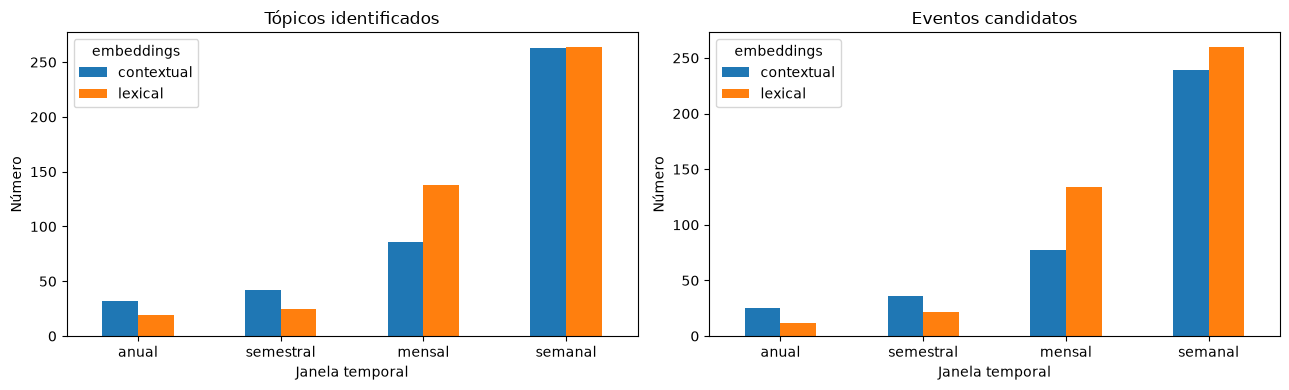

In [21]:
import matplotlib.pyplot as plt
resumos = []
for (tipo, versao), resultado in resultados.items():
    d, t, e = resultado["diagnosticos"], resultado["topicos"], resultado["eventos"]
    modeladas = d[d["estado"] == "modelada"]
    resumos.append({"janela": tipo, "embeddings": versao, "janelas_total": len(d),
                    "janelas_modeladas": len(modeladas), "janelas_insuficientes": len(d)-len(modeladas),
                    "topicos_total": len(t), "transicoes_avaliadas": resultado["transicoes_avaliadas"],
                    "eventos_total": len(e), "eventos_por_transicao": len(e) / resultado["transicoes_avaliadas"] if resultado["transicoes_avaliadas"] else None,
                    "ruido_medio": modeladas["proporcao_ruido"].mean(),
                    "maior_topico_medio": modeladas["proporcao_maior_topico"].mean()})
resumo = pd.DataFrame(resumos)
display(resumo)
resumo.to_csv(output_base / "resumo_comparativo.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, coluna, titulo in [(axes[0], "topicos_total", "Tópicos identificados"), (axes[1], "eventos_total", "Eventos candidatos")]:
    tabela = resumo.pivot(index="janela", columns="embeddings", values=coluna).reindex(JANELAS)
    tabela.plot.bar(ax=ax, title=titulo, rot=0)
    ax.set_xlabel("Janela temporal")
    ax.set_ylabel("Número")
plt.tight_layout()
plt.show()


## 5. Palavras e eventos por janela

Os rótulos seguintes são palavras representativas, não nomes atribuídos manualmente. Os CSV `topicos`, `eventos` e `amostra_intervencoes` contêm os detalhes completos. Para avaliar se um tópico é coerente, lê as intervenções da amostra.


In [22]:
for (tipo, versao), resultado in resultados.items():
    print(f"\n{'=' * 70}\n{tipo.upper()} — {versao.upper()}")
    print("Rótulos automáticos dos tópicos por janela (palavras c-TF-IDF):")
    topicos = resultado["topicos"]
    if topicos.empty:
        print("  Nenhum tópico válido.")
    for janela, grupo in topicos.groupby("janela", sort=False):
        print(f"\n  {janela} — {len(grupo)} tópicos")
        for linha in grupo.itertuples(index=False):
            print(f"    Tópico {linha.topico} ({linha.documentos} intervenções): {linha.palavras}")
    eventos = resultado["eventos"]
    print("\nEventos candidatos:")
    if eventos.empty:
        print("  Nenhum evento identificado entre janelas adjacentes modeladas.")
    else:
        for tipo_evento, numero in eventos["tipo"].value_counts().items():
            print(f"  {tipo_evento}: {numero}")
        print("  Exemplos de relações e respetivos descritores:")
        for linha in eventos.head(5).itertuples(index=False):
            print(f"    {linha.janela_origem} → {linha.janela_destino}: {linha.tipo} | {linha.palavras_origem} → {linha.palavras_destino or 'sem sucessor'}")



ANUAL — CONTEXTUAL
Rótulos automáticos dos tópicos por janela (palavras c-TF-IDF):

  2015-01-01 a 2015-12-31 — 11 tópicos
    Tópico 0 (10760 intervenções): sr, governo, presidente, sr presidente, srs, deputados, srs deputados, porque, deputado, aqui
    Tópico 1 (90 intervenções): declaração voto, declaração, voto, anunciar, sr presidente, presidente, presidente anunciar, voto sobre, sr, votação
    Tópico 2 (64 intervenções): xii, baixa, comissão, pcp, lei, baixa comissão, be, pcp baixa, recomenda, freguesia
    Tópico 3 (63 intervenções): declaração voto, declaração, voto, apresentará declaração, grupo parlamentar, apresentará, grupo, parlamentar, anunciar, anunciar grupo
    Tópico 4 (63 intervenções): interpelação mesa, mesa, interpelação, peço palavra, peço, presidente peço, sr presidente, presidente, palavra, mesa sobre
    Tópico 5 (46 intervenções): xii, presidente, entrada mesa, sr presidente, sr, entrada, comissão, mesa, baixa, presidente sr
    Tópico 6 (42 intervenções):

## 6. Avaliação

Compara a proporção de documentos no maior tópico, o ruído e os rótulos de cada período. Lê as intervenções e as relações antes de interpretar drift. Janelas não modeladas e eventos são sinalizados; números de tópicos são locais a cada janela. Como o texto e os embeddings mudam simultaneamente entre versões, esta comparação não isola o efeito individual da lematização ou das stopwords.
